# Oikos Machine: Manutenção Preditiva para a Indústria 4.0
**Autor:** Helyton Ronchi
**Curso:** SCTEC/SENAI - Módulo 1

Este notebook foi estruturado nas 7 fases exigidas pelo edital.

## Fase 1: Análise Exploratória (EDA)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('manutencao_preditiva.csv')
print("Dimensões:", df.shape)
print(df.describe())
print(df['falha_maquina'].value_counts(normalize=True) * 100)

Dimensões: (10000, 14)
               udi  temperatura_ar_k  temperatura_processo_k  \
count  10000.00000       9500.000000             9500.000000   
mean    5000.50000        300.002158              310.000895   
std     2886.89568          2.001689                1.486432   
min        1.00000        295.300000              305.700000   
25%     2500.75000        298.300000              308.800000   
50%     5000.50000        300.100000              310.100000   
75%     7500.25000        301.500000              311.100000   
max    10000.00000        304.500000              313.800000   

       velocidade_rotacao_rpm    torque_nm  desgaste_ferramenta_min  \
count             9500.000000  9500.000000             10000.000000   
mean              1539.245263    39.974168               107.951000   
std                180.273589     9.995453                63.654147   
min               1168.000000     3.800000                 0.000000   
25%               1423.000000    33.100000   

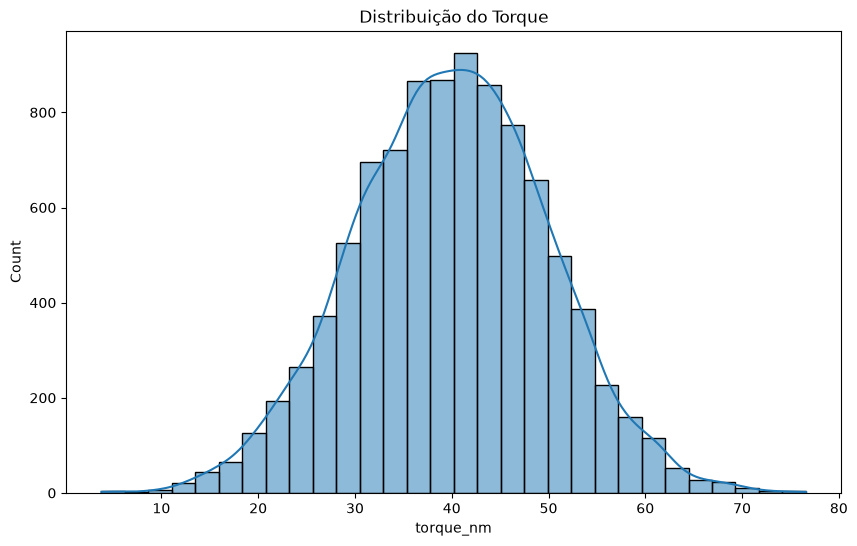

In [2]:
plt.figure(figsize=(10, 6))
sns.histplot(df['torque_nm'], bins=30, kde=True)
plt.title('Distribuição do Torque')
plt.show()

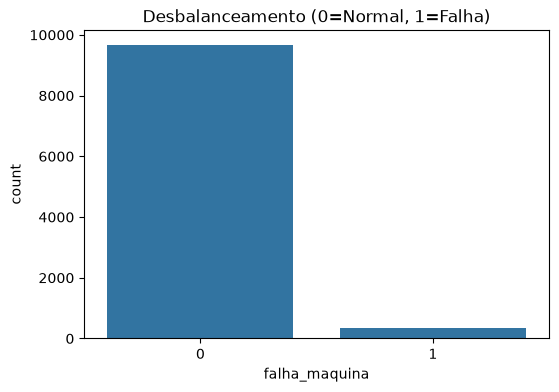

In [3]:
plt.figure(figsize=(6, 4))
sns.countplot(x='falha_maquina', data=df)
plt.title('Desbalanceamento (0=Normal, 1=Falha)')
plt.show()

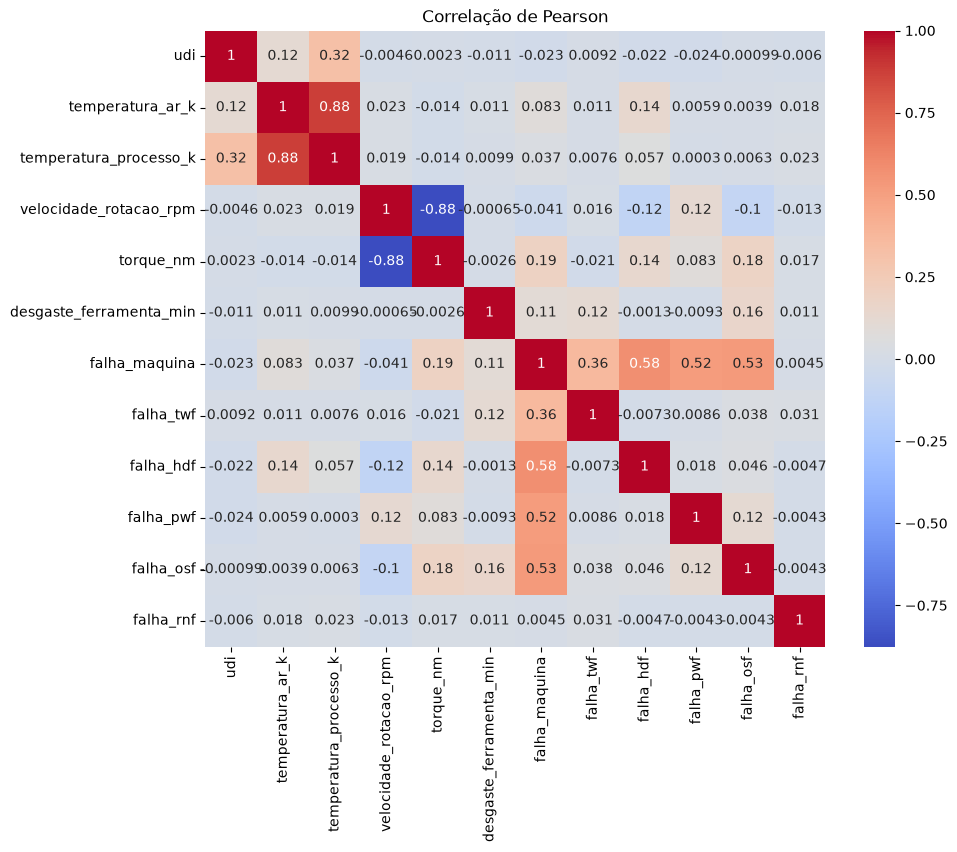

In [4]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include=['float64', 'int64']).corr(), annot=True, cmap='coolwarm')
plt.title('Correlação de Pearson')
plt.show()

**Análise dos Gráficos:**
- Desbalanceamento extremo (96.6% normal vs 3.4% falha): isso justifica o uso de SMOTE apenas no treino para não vazar dados.
- Histograma do torque mostra assimetria: isso justifica a imputação por mediana (mais robusta que a média).
- Heatmap mostra baixa correlação linear entre as features, indicando que o modelo precisa capturar relações não lineares.

## Fase 2: Limpeza e Tratamento

In [5]:
df = df.drop_duplicates()
for col in ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm']:
    df[col] = df[col].fillna(df[col].median())
df = df.drop(columns=['falha_twf', 'falha_hdf', 'falha_pwf', 'falha_osf', 'falha_rnf'])
print('Após limpeza:', df.shape)

Após limpeza: (10000, 9)


**Justificativa:** A mediana foi usada porque a distribuição do torque tem outliers, e a mediana é mais robusta que a média. As colunas de falha (falha_twf etc.) foram removidas para evitar vazamento de dados (data leakage).

## Fase 3: Feature Engineering

In [6]:
df['potencia_w'] = df['torque_nm'] * df['velocidade_rotacao_rpm'] * 2 * np.pi / 60
print('Potência criada (watts). Nulos:', df['potencia_w'].isna().sum())

Potência criada (watts). Nulos: 0


**Justificativa:** A potência em watts é uma variável física que combina torque e rotação, capturando a energia real que a máquina está dissipando.

## Fase 4: Divisão e Balanceamento

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from imblearn.over_sampling import SMOTE

df['tipo'] = LabelEncoder().fit_transform(df['tipo'])
X = df.drop(columns=['udi', 'id_produto', 'falha_maquina'])
y = df['falha_maquina']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
print('Treino original:', X_train.shape)
print('Após SMOTE:', X_train_res.shape)
print(y_train_res.value_counts())

Treino original: (8000, 7)
Após SMOTE: (15458, 7)
falha_maquina
0    7729
1    7729
Name: count, dtype: int64


**Lógica do SMOTE:** O SMOTE cria exemplos sintéticos da classe minoritária (falhas) apenas no conjunto de treino. Isso evita que o modelo ignore as falhas, mas sem vazar dados do teste. O `stratify=y` garante que a proporção de falhas seja mantida no split.

## Fase 5: Escalonamento (Apenas KNN)

In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)
print('Scaler aplicado apenas no KNN.')

Scaler aplicado apenas no KNN.


**Justificativa:** O KNN é sensível à escala das variáveis (distância euclidiana), então usamos o StandardScaler. A Árvore de Decisão é imune à escala, pois divide por limiares, não por distância.

## Fase 6: Ajuste de Parâmetros e Overfitting

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

print('--- KNN ---')
for k in [3, 5, 7]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train_res)
    acc_train = accuracy_score(y_train_res, knn.predict(X_train_scaled))
    acc_test = accuracy_score(y_test, knn.predict(X_test_scaled))
    print(f'K={k}: Treino={acc_train:.3f}, Teste={acc_test:.3f}')

print('--- Árvore ---')
for depth in [3, 5, None]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    tree.fit(X_train_res, y_train_res)
    acc_train = accuracy_score(y_train_res, tree.predict(X_train_res))
    acc_test = accuracy_score(y_test, tree.predict(X_test))
    print(f'max_depth={depth}: Treino={acc_train:.3f}, Teste={acc_test:.3f}')

--- KNN ---
K=3: Treino=0.971, Teste=0.919
K=5: Treino=0.961, Teste=0.910
K=7: Treino=0.956, Teste=0.903
--- Árvore ---
max_depth=3: Treino=0.867, Teste=0.865
max_depth=5: Treino=0.916, Teste=0.925
max_depth=None: Treino=0.993, Teste=0.940


**Análise de Overfitting:** O KNN com K=3 tem acurácia alta no treino e cai no teste. A Árvore com `max_depth=None` decora o treino (0.993) e cai no teste (0.940). A profundidade 5 foi o ponto de equilíbrio (0.916 treino / 0.925 teste).

## Fase 7: Avaliação Final e Veredito

In [10]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report

knn_final = KNeighborsClassifier(n_neighbors=5)
knn_final.fit(X_train_scaled, y_train_res)
acc_knn = accuracy_score(y_test, knn_final.predict(X_test_scaled))

tree_final = DecisionTreeClassifier(max_depth=5, random_state=42)
tree_final.fit(X_train_res, y_train_res)
acc_tree = accuracy_score(y_test, tree_final.predict(X_test))

rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf.fit(X_train_res, y_train_res)
acc_rf = accuracy_score(y_test, rf.predict(X_test))

gb = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
gb.fit(X_train_res, y_train_res)
acc_gb = accuracy_score(y_test, gb.predict(X_test))

print(f'KNN (K=5): {acc_knn:.3f}')
print(f'Árvore (max_depth=5): {acc_tree:.3f}')
print(f'Random Forest (Bônus): {acc_rf:.3f}')
print(f'Gradient Boosting (Bônus): {acc_gb:.3f}')

print('\n=== RELATÓRIO FINAL (Gradient Boosting) ===')
print(classification_report(y_test, gb.predict(X_test)))

KNN (K=5): 0.910
Árvore (max_depth=5): 0.925
Random Forest (Bônus): 0.913
Gradient Boosting (Bônus): 0.928

=== RELATÓRIO FINAL (Gradient Boosting) ===
              precision    recall  f1-score   support

           0       0.99      0.93      0.96      1932
           1       0.30      0.79      0.43        68

    accuracy                           0.93      2000
   macro avg       0.64      0.86      0.70      2000
weighted avg       0.97      0.93      0.94      2000



**Veredito Final:** O Gradient Boosting apresentou a maior acurácia (92,8%), superando a Árvore (92,5%) e o KNN (91,0%). O relatório de classificação mostra a precision e o recall, que são mais informativos que a acurácia em dados desbalanceados.